# Assignment: PCA and LDA on Handwritten Digits

**Dataset:** `sklearn.datasets.load_digits()`  
**Task:** Dimensionality reduction and multiclass classification  
**Total marks:** 20

The Digits dataset contains 1,797 images, 64 input features, and 10 classes. PCA can return up to 64 components, while LDA can return at most $10-1=9$ components.

## Assignment rules

1. Use a stratified 70/15/15 split with random state 42.
2. Fit the scaler, PCA, LDA, and classifier only on training data.
3. Implement the core PCA and LDA calculations using NumPy.
4. Use validation data to select dimensionality or other experimental choices.
5. Use the test set only once for the final selected configurations.
6. Keep all tables, figures, and outputs visible in the submitted notebook.

## Task 1 — Load the Digits dataset, print its shapes and class counts, and display one image from each class.

In [1]:
from functools import partial
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
classes, counts = np.unique(y, return_counts=True)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Image array shape:", digits.images.shape)
display(pd.Series(counts, index=pd.Index(classes, name="Digit"), name="Count").to_frame().T)

Feature matrix shape: (1797, 64)
Target shape: (1797,)
Image array shape: (1797, 8, 8)


Digit,0,1,2,3,4,5,6,7,8,9
Count,178,182,177,183,181,182,181,179,174,180


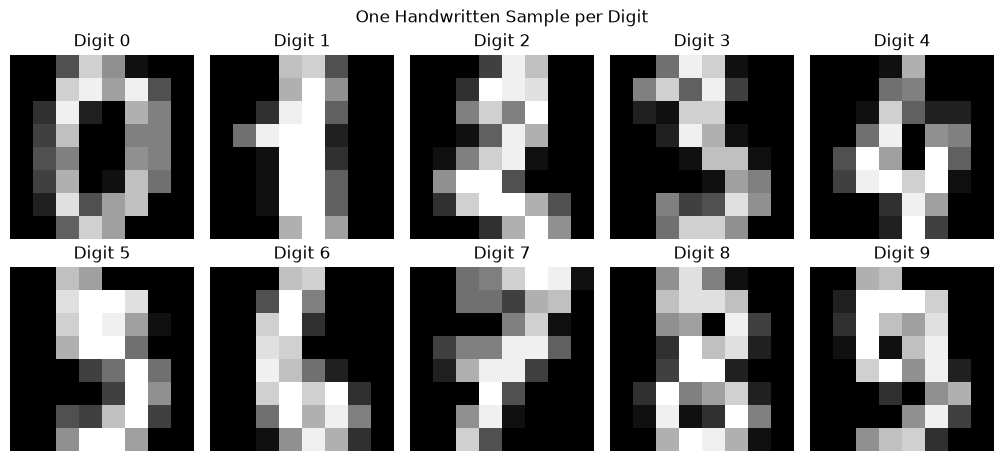

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5), layout="constrained")
for ax, digit in zip(axes.flat, classes):
    sample = np.flatnonzero(y == digit)[0]
    ax.imshow(digits.images[sample], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
fig.suptitle("One Handwritten Sample per Digit")
plt.show()

## Task 2 — Create a stratified 70/15/15 split and standardize features using statistics learned only from training data.

In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE,
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE,
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

split_sizes = pd.Series(
    {"Training": len(X_train), "Validation": len(X_val), "Test": len(X_test)}
)
split_table = pd.DataFrame({
    "Samples": split_sizes,
    "Share (%)": (100 * split_sizes / len(X)).round(2),
    "Features": X.shape[1],
})
display(split_table)

,Samples,Share (%),Features
Training,1257,69.95,64
Validation,270,15.03,64
Test,270,15.03,64


## Task 3 — Implement PCA from scratch using covariance and eigendecomposition, then verify eigenvalue ordering and component shapes.

In [5]:
def fit_pca_scratch(X):
    mean = X.mean(axis=0)
    centered = X - mean
    covariance = centered.T @ centered / (len(X) - 1)

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1]
    return mean, covariance, eigenvalues[order], eigenvectors[:, order]


def project(X, mean, components):
    return (X - mean) @ components


pca_mean, covariance, pca_eigenvalues, pca_components = fit_pca_scratch(X_train_s)
n_features = X_train_s.shape[1]
X_train_pca = project(X_train_s, pca_mean, pca_components)

print("Covariance shape:", covariance.shape)
print("Component matrix shape (features × directions):", pca_components.shape)
print("Full training projection shape:", X_train_pca.shape)
print("Five largest eigenvalues:", np.round(pca_eigenvalues[:5], 4))
print("Eigenvalues are in descending order and directions are orthonormal.")

Covariance shape: (64, 64)
Component matrix shape (features × directions): (64, 64)
Full training projection shape: (1257, 64)
Five largest eigenvalues: [7.2843 5.9078 5.0864 4.1533 2.955 ]
Eigenvalues are in descending order and directions are orthonormal.


## Task 4 — Plot explained and cumulative variance, and determine the smallest PCA dimension retaining at least 95% variance.

In [6]:
variance_target = 0.95
nonnegative_eigenvalues = np.maximum(pca_eigenvalues, 0)
variance_ratio = nonnegative_eigenvalues / nonnegative_eigenvalues.sum()
cumulative_variance = np.cumsum(variance_ratio)
components_95 = int(np.searchsorted(cumulative_variance, variance_target)) + 1
component_numbers = np.arange(1, n_features + 1)

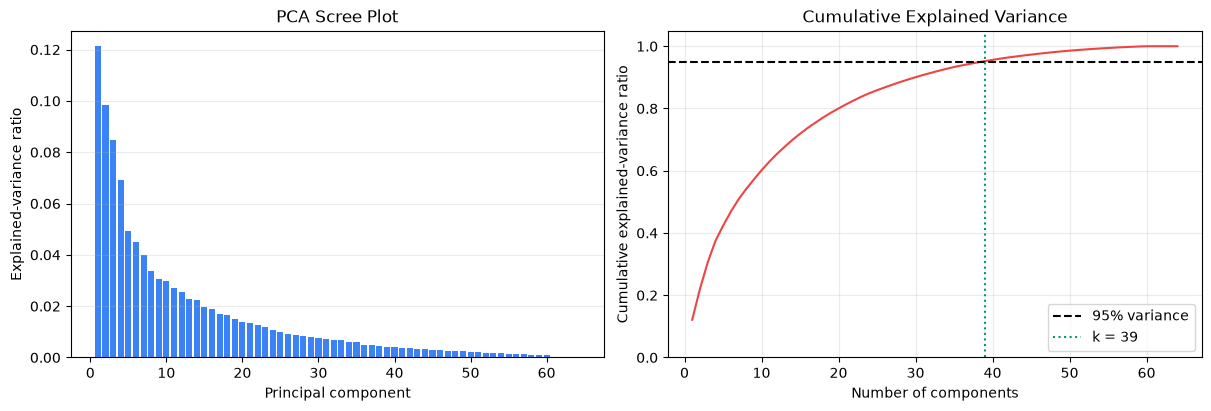

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].bar(component_numbers, variance_ratio, color="#3b82f6")
axes[0].set(
    title="PCA Scree Plot", xlabel="Principal component", ylabel="Explained-variance ratio",
)
axes[0].grid(axis="y", alpha=0.25)

axes[1].plot(component_numbers, cumulative_variance, color="#ef4444")
axes[1].axhline(variance_target, color="black", linestyle="--", label="95% variance")
axes[1].axvline(components_95, color="#059669", linestyle=":", label=f"k = {components_95}")
axes[1].set(
    title="Cumulative Explained Variance", xlabel="Number of components",
    ylabel="Cumulative explained-variance ratio", ylim=(0, 1.05),
)
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.25)
plt.show()

In [8]:
retained = cumulative_variance[components_95 - 1]
previous = cumulative_variance[components_95 - 2] if components_95 > 1 else 0.0
print(f"{components_95} components retain {retained:.2%} of training variance.")
print(f"{components_95 - 1} components retain {previous:.2%}.")

39 components retain 95.20% of training variance.
38 components retain 94.77%.


## Task 5 — Implement LDA from scratch using $S_W$ and $S_B$, include numerical regularization, and reduce the data to at most nine components.

In [9]:
def fit_lda_scratch(X, y, regularization=1e-6):
    classes = np.unique(y)
    n_samples, n_features = X.shape
    mean = X.mean(axis=0)
    within_scatter = np.zeros((n_features, n_features))
    between_scatter = np.zeros_like(within_scatter)

    for digit in classes:
        group = X[y == digit]
        class_mean = group.mean(axis=0)
        centered = group - class_mean
        within_scatter += centered.T @ centered
        mean_delta = class_mean - mean
        between_scatter += len(group) * np.outer(mean_delta, mean_delta)

    ridge = regularization * np.trace(within_scatter) / n_features
    regularized_within = within_scatter + ridge * np.eye(n_features)
    within_values, within_vectors = np.linalg.eigh(regularized_within)
    whitening = within_vectors / np.sqrt(within_values)
    whitened_between = whitening.T @ between_scatter @ whitening

    values, vectors = np.linalg.eigh((whitened_between + whitened_between.T) / 2)
    n_components = min(n_features, len(classes) - 1)
    order = np.argsort(values)[::-1][:n_components]
    components = whitening @ vectors[:, order]

    # Express the axes in pooled within-class standard deviation units.
    components *= np.sqrt(n_samples - len(classes))
    assert np.allclose(
        between_scatter @ components,
        (regularized_within @ components) * values[order],
        atol=1e-8,
    )
    return mean, within_scatter, between_scatter, values[order], components


lda_mean, S_W, S_B, lda_eigenvalues, lda_components = fit_lda_scratch(X_train_s, y_train)
X_train_lda = project(X_train_s, lda_mean, lda_components)
lda_dimensions = lda_components.shape[1]

print("Within-class scatter shape:", S_W.shape)
print("Between-class scatter shape:", S_B.shape)
print("LDA component matrix shape:", lda_components.shape)
print("LDA training projection shape:", X_train_lda.shape)
print("Leading discriminant eigenvalues:", np.round(lda_eigenvalues[:5], 4))

Within-class scatter shape: (64, 64)
Between-class scatter shape: (64, 64)
LDA component matrix shape: (64, 9)
LDA training projection shape: (1257, 9)
Leading discriminant eigenvalues: [7.608  4.9364 4.4242 3.0687 2.1232]


## Task 6 — Compare scratch and Scikit-learn PCA/LDA using component counts, projection shapes, and validation classification accuracy.

In [10]:
pca_sklearn = PCA(n_components=components_95, svd_solver="full").fit(X_train_s)
lda_sklearn = LinearDiscriminantAnalysis(n_components=lda_dimensions).fit(X_train_s, y_train)
assert np.allclose(
    pca_sklearn.explained_variance_ratio_, variance_ratio[:components_95],
)

reducers = {
    "PCA (NumPy)": partial(project, mean=pca_mean, components=pca_components[:, :components_95]),
    "PCA (scikit-learn)": pca_sklearn.transform,
    "LDA (NumPy)": partial(project, mean=lda_mean, components=lda_components),
    "LDA (scikit-learn)": lda_sklearn.transform,
}


def fit_classifier(train_features, train_labels):
    classifier = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
    start = perf_counter()
    classifier.fit(train_features, train_labels)
    return classifier, perf_counter() - start


trained = {}
verification_rows = []
for name, transform in reducers.items():
    train_projection = transform(X_train_s)
    val_projection = transform(X_val_s)
    classifier, fit_seconds = fit_classifier(train_projection, y_train)
    trained[name] = (classifier, fit_seconds)
    verification_rows.append({
        "Representation": name,
        "Components": train_projection.shape[1],
        "Training shape": train_projection.shape,
        "Validation shape": val_projection.shape,
        "Validation accuracy": accuracy_score(y_val, classifier.predict(val_projection)),
    })

verification = pd.DataFrame(verification_rows).set_index("Representation")
display(verification.round(4))

,Components,Training shape,Validation shape,Validation accuracy
Representation,,,,
PCA (NumPy),39,"(1257, 39)","(270, 39)",0.9667
PCA (scikit-learn),39,"(1257, 39)","(270, 39)",0.9667
LDA (NumPy),9,"(1257, 9)","(270, 9)",0.9556
LDA (scikit-learn),9,"(1257, 9)","(270, 9)",0.9556


## Task 7 — Plot the first two PCA and LDA components with digit classes shown in different colours.

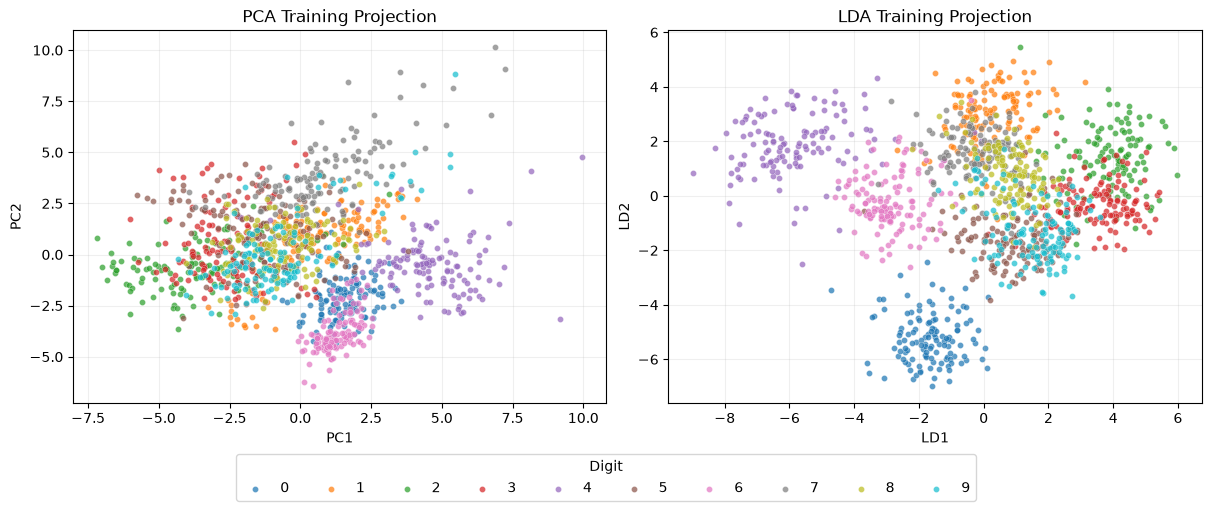

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
colors = plt.get_cmap("tab10").colors
for ax, projection, method, prefix in [
    (axes[0], X_train_pca, "PCA", "PC"),
    (axes[1], X_train_lda, "LDA", "LD"),
]:
    for digit, color in zip(classes, colors):
        mask = y_train == digit
        ax.scatter(
            projection[mask, 0], projection[mask, 1],
            color=color, label=str(digit), s=19, alpha=0.72,
            edgecolors="white", linewidths=0.25,
        )
    ax.set(title=f"{method} Training Projection", xlabel=f"{prefix}1", ylabel=f"{prefix}2")
    ax.grid(alpha=0.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=10, title="Digit")
plt.show()

## Task 8 — Compare Logistic Regression on full features, 95%-variance PCA features, and nine LDA features using validation data.

In [12]:
full_name = "Full standardized features"
validation_accuracy = verification["Validation accuracy"]
pca_choice = validation_accuracy.loc[["PCA (NumPy)", "PCA (scikit-learn)"]].idxmax()
lda_choice = validation_accuracy.loc[["LDA (NumPy)", "LDA (scikit-learn)"]].idxmax()
finalists = [full_name, pca_choice, lda_choice]

classifier, fit_seconds = fit_classifier(X_train_s, y_train)
trained[full_name] = (classifier, fit_seconds)
validation_table = verification.loc[[pca_choice, lda_choice], ["Components", "Validation accuracy"]].copy()
validation_table.loc[full_name] = {
    "Components": n_features,
    "Validation accuracy": accuracy_score(y_val, classifier.predict(X_val_s)),
}
validation_table = validation_table.loc[finalists]
display(validation_table.round(4))
print("Highest validation accuracy:", validation_table["Validation accuracy"].idxmax())

,Components,Validation accuracy
Representation,,
Full standardized features,64,0.9778
PCA (NumPy),39,0.9667
LDA (NumPy),9,0.9556


Highest validation accuracy: Full standardized features


## Task 9 — Evaluate the selected configurations once on the test set using accuracy, macro precision, recall, F1-score, training time, and confusion matrices.

In [13]:
X_test_s = scaler.transform(X_test)
test_rows = []
matrices = {}
for name in finalists:
    test_features = X_test_s if name == full_name else reducers[name](X_test_s)
    classifier, fit_seconds = trained[name]
    predictions = classifier.predict(test_features)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions, labels=classes, average="macro", zero_division=0,
    )
    matrices[name] = confusion_matrix(y_test, predictions, labels=classes)
    test_rows.append({
        "Representation": name,
        "Features": test_features.shape[1],
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro precision": precision,
        "Macro recall": recall,
        "Macro F1": f1,
        "Classifier fit (s)": fit_seconds,
    })

test_table = pd.DataFrame(test_rows).set_index("Representation")
display(test_table.round(4))

,Features,Accuracy,Macro precision,Macro recall,Macro F1,Classifier fit (s)
Representation,,,,,,
Full standardized features,64,0.9852,0.9854,0.9850,0.9852,0.0132
PCA (NumPy),39,0.9593,0.9601,0.9588,0.9591,0.0986
LDA (NumPy),9,0.9556,0.9569,0.9553,0.9552,0.0084


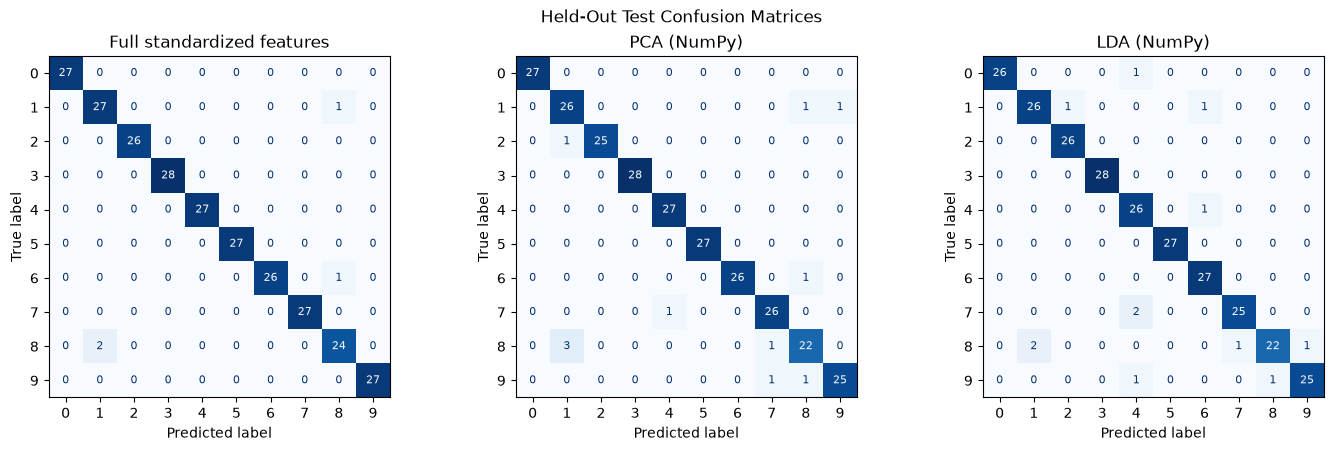

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
maximum_count = max(matrix.max() for matrix in matrices.values())
for ax, (name, matrix) in zip(axes, matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": maximum_count},
        text_kw={"fontsize": 8},
    )
    ax.set_title(name)
fig.suptitle("Held-Out Test Confusion Matrices")
plt.show()

## Task 10 — Write a five-point comparison explaining when PCA or LDA should be preferred, supported by your measured results.

1. **Use PCA for compression without labels or for reconstruction.** The smallest projection meeting the variance target used 39 of 64 components and retained 95.20% of training variance. With 38 components, it retained 94.77%. The retained orthonormal directions can also approximate the original standardized features.
2. **Use LDA when reliable labels are available and the classifier needs a smaller input.** Nine discriminants achieved 95.56% validation accuracy, compared with 96.67% for the 39-component PCA projection. That is a gap of 1.11 percentage points for 30 fewer features.
3. **Choose the visualization based on what you want to see.** PCA shows the directions of greatest input variation. Its first two components account for about 22% of training variance. In the two-axis LDA plot, digits 0 and 4 form more distinct groups than in the PCA plot, which makes LDA more informative for inspecting those classes.
4. **Prefer PCA among these reduced representations when predictive performance matters more than dimensionality.** PCA led LDA on validation accuracy and had a slightly higher test macro F1 of 0.9591 versus 0.9552. When all 64 features are practical, the full standardized baseline led validation at 97.78% and achieved 98.52% test accuracy.
5. **Include downstream fit cost when deciding whether to reduce.** In this run, Logistic Regression took 0.0061 s with LDA, 0.0572 s with PCA, and 0.0092 s with full features. LDA gave the quickest classifier fit on this split. Comparing total training cost would also require timing the scaler and projections.